Inventory Business Logic

This notebook converts demand forecasts into practical inventory decisions:

1. Predicted demand
2. Stockout risk
3. Safety stock
4. Reorder quantity
5. Stock coverage
6. Healthy / Stockout Risk / Overstocked status
7. Slow-moving products
8. Priority reorder list
9. Business summary

Expected project structure:

```text
aquatic-inventory-ml/
├── data/
│   └── aquatic_demand_ml_dataset.csv
├── notebooks/
│   ├── 01_eda.ipynb
│   ├── 02_modeling.ipynb
│   └── 03_business_logic.ipynb
├── model.pkl
└── README.md
```

The notebook first tries to load `model.pkl`. If your Phase 3 model has a different filename or location, change the `MODEL_PATH` variable in the setup cell.


In [33]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

DATA_PATH = "../data/aquatic_demand_ml_dataset.csv"
MODEL_PATH = "../model.pkl"

print("Business Logic notebook started.")
print("Dataset path:", DATA_PATH)
print("Model path:", MODEL_PATH)


Business Logic notebook started.
Dataset path: ../data/aquatic_demand_ml_dataset.csv
Model path: ../model.pkl


In [34]:
# Load the original dataset
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())


Dataset shape: (12960, 52)

Columns:
['month_start', 'category', 'subcategory', 'brand', 'product_line', 'product_line_id', 'location', 'split', 'demand', 'year', 'month_num', 'quarter', 'days_in_month', 'month_index', 'season', 'category_code', 'subcategory_code', 'brand_code', 'location_code', 'season_code', 'demand_lag_1', 'demand_lag_2', 'demand_lag_3', 'demand_roll_mean_3', 'demand_roll_std_3', 'demand_roll_mean_6', 'demand_expanding_mean', 'demand_growth_1', 'demand_per_day_lag_1', 'avg_price', 'avg_discount', 'avg_final_price', 'avg_stock', 'low_stock_share', 'avg_rating', 'avg_review_count', 'return_rate', 'delay_rate', 'avg_shipping_days', 'avg_stock_lag_1', 'low_stock_share_lag_1', 'avg_rating_lag_1', 'avg_review_count_lag_1', 'return_rate_lag_1', 'delay_rate_lag_1', 'is_slow_moving', 'sim_current_stock', 'sim_stockout_risk', 'sim_reorder_qty', 'ana_revenue', 'ana_unique_customers', 'ana_demand_per_day']


,month_start,category,subcategory,brand,product_line,product_line_id,location,split,demand,year,...,avg_review_count_lag_1,return_rate_lag_1,delay_rate_lag_1,is_slow_moving,sim_current_stock,sim_stockout_risk,sim_reorder_qty,ana_revenue,ana_unique_customers,ana_demand_per_day
0,2024-10-01,Aqua Equipments,Air Filter,Boyu,Air Filter | Boyu,1,Bangalore,train,38,2024,...,40.8974,0.1282,0.2821,0,61,Low,0,1347380.75,38,1.226
1,2024-11-01,Aqua Equipments,Air Filter,Boyu,Air Filter | Boyu,1,Bangalore,train,38,2024,...,32.7632,0.1053,0.3158,0,47,Medium,0,1096050.66,38,1.267
2,2024-12-01,Aqua Equipments,Air Filter,Boyu,Air Filter | Boyu,1,Bangalore,train,23,2024,...,30.9474,0.0789,0.3421,0,63,Low,0,795745.12,23,0.742
3,2025-01-01,Aqua Equipments,Air Filter,Boyu,Air Filter | Boyu,1,Bangalore,train,33,2025,...,18.0000,0.0870,0.3478,1,34,Medium,0,1034269.42,33,1.065
4,2025-02-01,Aqua Equipments,Air Filter,Boyu,Air Filter | Boyu,1,Bangalore,train,35,2025,...,43.5758,0.0606,0.3636,1,30,High,5,1143074.27,35,1.250


1. Detect the important columns

The notebook tries to find the demand, stock, product and date columns automatically.  
If a column is not detected correctly, edit the four variables in the next cell.


In [35]:
# Try to detect common column names automatically.
def find_column(columns, candidates):
    lower_map = {str(c).lower(): c for c in columns}
    for candidate in candidates:
        if candidate.lower() in lower_map:
            return lower_map[candidate.lower()]
    for c in columns:
        cl = str(c).lower()
        if any(candidate.lower() in cl for candidate in candidates):
            return c
    return None

DEMAND_COL = find_column(df.columns, ["demand", "orders", "monthly_demand"])
STOCK_COL = find_column(df.columns, [
    "current_stock", "stock", "last_month_stock", "inventory", "stock_level"
])
PRODUCT_COL = find_column(df.columns, [
    "product_type", "product", "product_category", "category"
])
DATE_COL = find_column(df.columns, ["month", "date", "year_month"])

print("Detected demand column :", DEMAND_COL)
print("Detected stock column  :", STOCK_COL)
print("Detected product column:", PRODUCT_COL)
print("Detected date column   :", DATE_COL)

if DEMAND_COL is None:
    raise ValueError("Could not find the demand column. Set DEMAND_COL manually.")
if STOCK_COL is None:
    raise ValueError(
        "Could not find a current/stock column. Set STOCK_COL manually. "
        "The inventory calculations need a stock value."
    )


Detected demand column : demand
Detected stock column  : avg_stock
Detected product column: category
Detected date column   : month_start


2. Create demand predictions

If `model.pkl` exists, the notebook attempts to use it.  
If the saved model is a full sklearn pipeline, it can directly predict from the feature columns.

If your Phase 3 notebook already contains a prediction column, the notebook can use that instead.


In [36]:
PRED_COL = find_column(df.columns, [
    "predicted_demand", "prediction", "predicted", "forecast"
])

if PRED_COL is not None:
    df["predicted_demand"] = pd.to_numeric(df[PRED_COL], errors="coerce")
    print("Using existing prediction column:", PRED_COL)

elif os.path.exists(MODEL_PATH):
    model = joblib.load(MODEL_PATH)
    print("Loaded model:", type(model).__name__)

    # Remove the target from the feature set.
    # A saved sklearn Pipeline should handle preprocessing itself.
    feature_cols = [c for c in df.columns if c != DEMAND_COL]

    # Avoid accidental leakage from an already-created prediction column.
    feature_cols = [
        c for c in feature_cols
        if str(c).lower() not in {"predicted_demand", "prediction", "predicted"}
    ]

    try:
        df["predicted_demand"] = model.predict(df[feature_cols])
        print("Predictions created successfully.")
    except Exception as e:
        print("\nThe saved model could not predict directly from this dataframe.")
        print("Reason:", e)
        print(
            "\nUse the exact feature/preprocessing code from 02_modeling.ipynb "
            "to create predicted_demand, then rerun the business-logic cells."
        )
        raise
else:
    raise FileNotFoundError(
        "No predicted_demand column and no model.pkl found. "
        "Save your Phase 3 model as ../model.pkl or create a predicted_demand column."
    )

df["predicted_demand"] = pd.to_numeric(
    df["predicted_demand"], errors="coerce"
).clip(lower=0)

df[["predicted_demand"]].describe()


Loaded model: Pipeline
Predictions created successfully.


,predicted_demand
count,12960.000000
mean,51.029293
std,19.076763
min,29.277298
25%,37.272379
50%,46.280596
75%,47.725825
max,101.990295


3. Prepare stock and calculate the inventory gap

We compare available stock with expected demand.

**Stock gap = Current Stock − Predicted Demand**

A negative gap means expected demand is greater than available stock.


In [37]:
df["current_stock"] = pd.to_numeric(
    df[STOCK_COL],
    errors="coerce"
).fillna(0)

df["stock_gap"] = (
    df["current_stock"] - df["predicted_demand"]
)

df["stockout_risk"] = np.where(
    df["stock_gap"] < 0,
    "High",
    "Low"
)

display(
    df[
        [
            PRODUCT_COL,
            "predicted_demand",
            "current_stock",
            "stock_gap",
            "stockout_risk"
        ]
    ].head(10)
)

,category,predicted_demand,current_stock,stock_gap,stockout_risk
0,Aqua Equipments,36.159172,241.9474,205.788228,Low
1,Aqua Equipments,34.498264,221.1579,186.659636,Low
2,Aqua Equipments,35.698406,241.7826,206.084194,Low
3,Aqua Equipments,35.816135,268.0606,232.244465,Low
4,Aqua Equipments,32.438507,286.6857,254.247193,Low
5,Aqua Equipments,35.843567,253.3448,217.501233,Low
6,Aqua Equipments,34.464882,225.9000,191.435118,Low
7,Aqua Equipments,35.550678,254.2632,218.712522,Low
8,Aqua Equipments,34.389832,252.5652,218.175368,Low
9,Aqua Equipments,35.786610,222.1429,186.356290,Low


4. Add Safety Stock and Calculate Inventory Decisions

For this academic/business prototype, we use 10% safety stock.

This is an assumption, not a universal industry rule. In a real company, safety stock would depend on lead time, demand variability and service-level targets.

Safety stock = Predicted demand × 10%

Target stock = Predicted demand + Safety stock

Reorder quantity = max(Target stock − Current stock, 0)

If the current stock is below the target stock, the system recommends the required reorder quantity.

If the current stock is already above the target stock, the system calculates excess stock:

Excess stock = max(Current stock − Target stock, 0)

This helps the business identify whether it should reorder inventory or focus on reducing/optimizing excess inventory.

In [38]:
# Safety stock and inventory decision calculations

SAFETY_STOCK_RATE = 0.10

df["safety_stock"] = (
    df["predicted_demand"] * SAFETY_STOCK_RATE
)

df["target_stock"] = (
    df["predicted_demand"] + df["safety_stock"]
)

df["reorder_quantity"] = (
    df["target_stock"] - df["current_stock"]
).clip(lower=0)

df["reorder_quantity"] = np.ceil(
    df["reorder_quantity"]
).astype(int)

df["excess_stock"] = (
    df["current_stock"] - df["target_stock"]
).clip(lower=0)

df["excess_stock"] = np.floor(
    df["excess_stock"]
).astype(int)

display(
    df[
        [
            PRODUCT_COL,
            "predicted_demand",
            "current_stock",
            "safety_stock",
            "target_stock",
            "reorder_quantity",
            "excess_stock"
        ]
    ].head(10)
)

,category,predicted_demand,current_stock,safety_stock,target_stock,reorder_quantity,excess_stock
0,Aqua Equipments,36.159172,241.9474,3.615917,39.775089,0,202
1,Aqua Equipments,34.498264,221.1579,3.449826,37.948090,0,183
2,Aqua Equipments,35.698406,241.7826,3.569841,39.268246,0,202
3,Aqua Equipments,35.816135,268.0606,3.581614,39.397751,0,228
4,Aqua Equipments,32.438507,286.6857,3.243851,35.682358,0,251
5,Aqua Equipments,35.843567,253.3448,3.584357,39.427925,0,213
6,Aqua Equipments,34.464882,225.9000,3.446488,37.911369,0,187
7,Aqua Equipments,35.550678,254.2632,3.555068,39.105747,0,215
8,Aqua Equipments,34.389832,252.5652,3.438983,37.828815,0,214
9,Aqua Equipments,35.786610,222.1429,3.578661,39.365273,0,182


In [39]:
# Calculate stock coverage and inventory status
df["stock_coverage_months"] = (
    df["current_stock"] /
    df["predicted_demand"].replace(0, np.nan)
)

def inventory_status(row):
    if row["predicted_demand"] <= 0:
        return "No Forecast"
    if row["stock_coverage_months"] < 1:
        return "Stockout Risk"
    elif row["stock_coverage_months"] <= 2:
        return "Healthy"
    else:
        return "Overstocked"

df["inventory_status"] = df.apply(
    inventory_status,
    axis=1
)

display(
    df[
        [
            PRODUCT_COL,
            "predicted_demand",
            "current_stock",
            "stock_coverage_months",
            "inventory_status"
        ]
    ].head(15)
)

,category,predicted_demand,current_stock,stock_coverage_months,inventory_status
0,Aqua Equipments,36.159172,241.9474,6.691176,Overstocked
1,Aqua Equipments,34.498264,221.1579,6.410696,Overstocked
2,Aqua Equipments,35.698406,241.7826,6.772924,Overstocked
3,Aqua Equipments,35.816135,268.0606,7.484353,Overstocked
4,Aqua Equipments,32.438507,286.6857,8.837820,Overstocked
5,Aqua Equipments,35.843567,253.3448,7.068069,Overstocked
6,Aqua Equipments,34.464882,225.9000,6.554498,Overstocked
7,Aqua Equipments,35.550678,254.2632,7.152134,Overstocked
8,Aqua Equipments,34.389832,252.5652,7.344183,Overstocked
9,Aqua Equipments,35.786610,222.1429,6.207431,Overstocked


5. Calculate stock coverage

Stock coverage estimates how many months of predicted demand the current inventory can cover.

**Stock coverage = Current Stock / Predicted Demand**

For this project:

- `< 1` month → Stockout Risk
- `1 to 2` months → Healthy
- `> 2` months → Overstocked

These thresholds are project assumptions and can be changed later.


In [40]:
df["stock_coverage_months"] = (
    df["current_stock"] /
    df["predicted_demand"].replace(0, np.nan)
)

def inventory_status(row):
    if row["predicted_demand"] <= 0:
        return "No Forecast"
    if row["stock_coverage_months"] < 1:
        return "Stockout Risk"
    elif row["stock_coverage_months"] <= 2:
        return "Healthy"
    else:
        return "Overstocked"

df["inventory_status"] = df.apply(inventory_status, axis=1)

display(
    df[[
        PRODUCT_COL,
        "predicted_demand",
        "current_stock",
        "stock_coverage_months",
        "inventory_status"
    ]].head(15)
)


,category,predicted_demand,current_stock,stock_coverage_months,inventory_status
0,Aqua Equipments,36.159172,241.9474,6.691176,Overstocked
1,Aqua Equipments,34.498264,221.1579,6.410696,Overstocked
2,Aqua Equipments,35.698406,241.7826,6.772924,Overstocked
3,Aqua Equipments,35.816135,268.0606,7.484353,Overstocked
4,Aqua Equipments,32.438507,286.6857,8.837820,Overstocked
5,Aqua Equipments,35.843567,253.3448,7.068069,Overstocked
6,Aqua Equipments,34.464882,225.9000,6.554498,Overstocked
7,Aqua Equipments,35.550678,254.2632,7.152134,Overstocked
8,Aqua Equipments,34.389832,252.5652,7.344183,Overstocked
9,Aqua Equipments,35.786610,222.1429,6.207431,Overstocked


6. Find slow-moving products

A product is treated as slow-moving when its average historical demand falls in the **bottom 25%** of products.

This is a relative definition, so it adapts to this dataset.


In [41]:
slow_product = (
    df.groupby(PRODUCT_COL, dropna=False)[DEMAND_COL]
      .mean()
      .reset_index(name="average_historical_demand")
)

slow_threshold = slow_product["average_historical_demand"].quantile(0.25)

slow_product["slow_moving"] = (
    slow_product["average_historical_demand"] <= slow_threshold
)

slow_product = slow_product.sort_values("average_historical_demand")

print("Slow-moving threshold:",
      round(slow_threshold, 2))

display(slow_product.head(10))


Slow-moving threshold: 46.2


,category,average_historical_demand,slow_moving
0,Aqua Equipments,34.676852,True
1,Aquatic Pet,46.196914,True
3,Fish Food,46.479167,False
4,Water Treatment,69.095370,False
2,Aquatic Plants,69.124537,False


In [42]:
# Combine slow-moving information with current inventory information

slow_product_details = (
    df.groupby(PRODUCT_COL, dropna=False)
      .agg(
          average_historical_demand=(DEMAND_COL, "mean"),
          predicted_demand=("predicted_demand", "mean"),
          current_stock=("current_stock", "mean"),
          excess_stock=("excess_stock", "mean"),
          stock_coverage_months=("stock_coverage_months", "mean")
      )
      .reset_index()
)

# Use the bottom 25% of average historical demand
slow_threshold = slow_product_details[
    "average_historical_demand"
].quantile(0.25)

slow_product_details["slow_moving"] = (
    slow_product_details["average_historical_demand"]
    <= slow_threshold
)

slow_product_details = slow_product_details[
    slow_product_details["slow_moving"]
].sort_values(
    "average_historical_demand"
)

print(
    "Slow-moving demand threshold:",
    round(slow_threshold, 2)
)

display(
    slow_product_details[
        [
            PRODUCT_COL,
            "average_historical_demand",
            "predicted_demand",
            "current_stock",
            "excess_stock",
            "stock_coverage_months",
            "slow_moving"
        ]
    ].head(15)
)

Slow-moving demand threshold: 46.2


,category,average_historical_demand,predicted_demand,current_stock,excess_stock,stock_coverage_months,slow_moving
0,Aqua Equipments,34.676852,34.842930,250.134497,211.314815,7.187082,True
1,Aquatic Pet,46.196914,46.208599,249.934426,198.606481,5.415470,True


In [43]:
# Create priority reorder list

reorder_list = (
    df[df["reorder_quantity"] > 0]
    .copy()
    .sort_values(
        ["stockout_risk", "reorder_quantity"],
        ascending=[True, False]
    )
)

priority_columns = [
    PRODUCT_COL,
    "predicted_demand",
    "current_stock",
    "stock_gap",
    "safety_stock",
    "target_stock",
    "reorder_quantity",
    "excess_stock",
    "stock_coverage_months",
    "inventory_status"
]

display(
    reorder_list[priority_columns].head(20)
)

print(
    "Records requiring reorder:",
    len(reorder_list)
)

print(
    "Total units to reorder:",
    int(reorder_list["reorder_quantity"].sum())
)

,category,predicted_demand,current_stock,stock_gap,safety_stock,target_stock,reorder_quantity,excess_stock,stock_coverage_months,inventory_status


Records requiring reorder: 0
Total units to reorder: 0


9. Business summary

This gives the main numbers that can later be shown directly on the Streamlit dashboard.


In [44]:
# Overall business summary

summary = {
    "Total records analysed": len(df),

    "High stockout-risk records": int(
        (df["inventory_status"] == "Stockout Risk").sum()
    ),

    "Healthy records": int(
        (df["inventory_status"] == "Healthy").sum()
    ),

    "Overstocked records": int(
        (df["inventory_status"] == "Overstocked").sum()
    ),

    "No forecast records": int(
        (df["inventory_status"] == "No Forecast").sum()
    ),

    "Records requiring reorder": int(
        (df["reorder_quantity"] > 0).sum()
    ),

    "Total units recommended for reorder": int(
        df["reorder_quantity"].sum()
    ),

    "Total excess stock": int(
        df["excess_stock"].sum()
    ),

    "Average stock coverage (months)": round(
        df["stock_coverage_months"].mean(), 2
    )
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Metric", "Value"]
)

display(summary_df)

,Metric,Value
0,Total records analysed,12960.0
1,High stockout-risk records,0.0
2,Healthy records,0.0
3,Overstocked records,12960.0
4,No forecast records,0.0
5,Records requiring reorder,0.0
6,Total units recommended for reorder,0.0
7,Total excess stock,2503265.0
8,Average stock coverage (months),5.4


10. Visualise inventory status


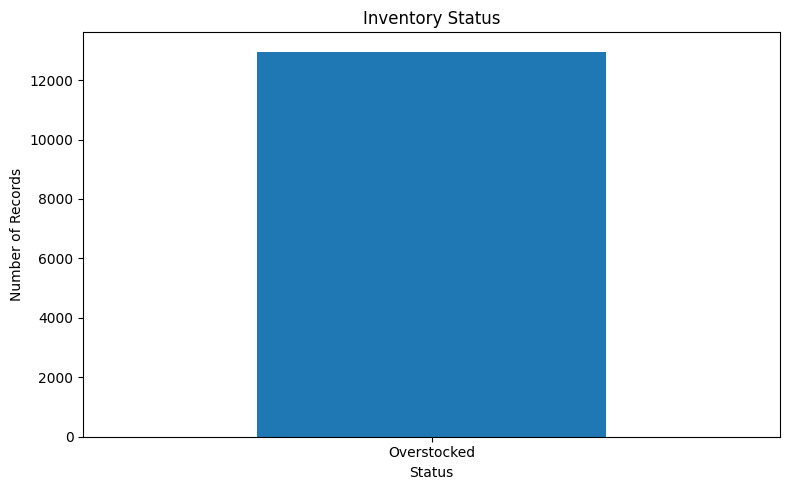

In [45]:
status_counts = df["inventory_status"].value_counts()

plt.figure(figsize=(8, 5))
status_counts.plot(kind="bar")
plt.title("Inventory Status")
plt.xlabel("Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


11. Top products requiring reorder


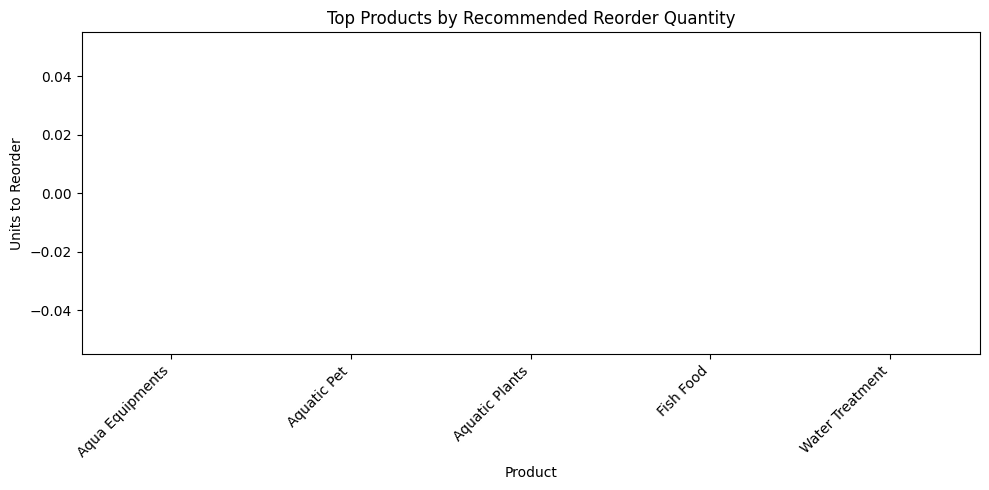

In [46]:
top_reorder = (
    df.groupby(PRODUCT_COL)["reorder_quantity"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10, 5))
top_reorder.plot(kind="bar")
plt.title("Top Products by Recommended Reorder Quantity")
plt.xlabel("Product")
plt.ylabel("Units to Reorder")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


12. Save the business-decision output

The final CSV can later be used by the Streamlit dashboard.


In [47]:
# Prepare final Phase 4 business output

output_columns = [
    c for c in [
        DATE_COL,
        PRODUCT_COL,
        "predicted_demand",
        "current_stock",
        "stock_gap",
        "safety_stock",
        "target_stock",
        "reorder_quantity",
        "excess_stock",
        "stock_coverage_months",
        "inventory_status"
    ]
    if c is not None and c in df.columns
]

business_output = df[output_columns].copy()

output_path = "../data/inventory_business_output.csv"

business_output.to_csv(
    output_path,
    index=False
)

print("Saved:", output_path)
print("Rows:", len(business_output))

display(business_output.head(10))


Saved: ../data/inventory_business_output.csv
Rows: 12960


,month_start,category,predicted_demand,current_stock,stock_gap,safety_stock,target_stock,reorder_quantity,excess_stock,stock_coverage_months,inventory_status
0,2024-10-01,Aqua Equipments,36.159172,241.9474,205.788228,3.615917,39.775089,0,202,6.691176,Overstocked
1,2024-11-01,Aqua Equipments,34.498264,221.1579,186.659636,3.449826,37.948090,0,183,6.410696,Overstocked
2,2024-12-01,Aqua Equipments,35.698406,241.7826,206.084194,3.569841,39.268246,0,202,6.772924,Overstocked
3,2025-01-01,Aqua Equipments,35.816135,268.0606,232.244465,3.581614,39.397751,0,228,7.484353,Overstocked
4,2025-02-01,Aqua Equipments,32.438507,286.6857,254.247193,3.243851,35.682358,0,251,8.837820,Overstocked
5,2025-03-01,Aqua Equipments,35.843567,253.3448,217.501233,3.584357,39.427925,0,213,7.068069,Overstocked
6,2025-04-01,Aqua Equipments,34.464882,225.9000,191.435118,3.446488,37.911369,0,187,6.554498,Overstocked
7,2025-05-01,Aqua Equipments,35.550678,254.2632,218.712522,3.555068,39.105747,0,215,7.152134,Overstocked
8,2025-06-01,Aqua Equipments,34.389832,252.5652,218.175368,3.438983,37.828815,0,214,7.344183,Overstocked
9,2025-07-01,Aqua Equipments,35.786610,222.1429,186.356290,3.578661,39.365273,0,182,6.207431,Overstocked


In [48]:
# Check inventory and reorder calculations
check = df[
    [
        PRODUCT_COL,
        "predicted_demand",
        "current_stock",
        "stock_gap"
    ]
].copy()

SAFETY_STOCK_RATE = 0.10

check["safety_stock"] = (
    check["predicted_demand"] * SAFETY_STOCK_RATE
)

check["target_stock"] = (
    check["predicted_demand"] +
    check["safety_stock"]
)

check["reorder_quantity"] = (
    check["target_stock"] -
    check["current_stock"]
).clip(lower=0)

check["reorder_quantity"] = np.ceil(
    check["reorder_quantity"]
).astype(int)

check["excess_stock"] = (
    check["current_stock"] -
    check["target_stock"]
).clip(lower=0)

check["excess_stock"] = np.floor(
    check["excess_stock"]
).astype(int)

check["stock_coverage_months"] = np.where(
    check["predicted_demand"] > 0,
    check["current_stock"] / check["predicted_demand"],
    np.nan
)

check["inventory_status"] = np.select(
    [
        check["predicted_demand"] <= 0,
        check["stock_coverage_months"] < 1,
        check["stock_coverage_months"] <= 2
    ],
    [
        "No Forecast",
        "Stockout Risk",
        "Healthy"
    ],
    default="Overstocked"
)

display(
    check[
        [
            PRODUCT_COL,
            "predicted_demand",
            "current_stock",
            "safety_stock",
            "target_stock",
            "reorder_quantity",
            "excess_stock",
            "stock_coverage_months",
            "inventory_status"
        ]
    ].head(20)
)

print("Records checked:", len(check))
print("Total predicted demand:", round(check["predicted_demand"].sum(), 2))
print("Total current stock:", round(check["current_stock"].sum(), 2))
print("Total reorder quantity:", int(check["reorder_quantity"].sum()))
print("Total excess stock:", int(check["excess_stock"].sum()))

print("\nInventory status:")
print(check["inventory_status"].value_counts())

,category,predicted_demand,current_stock,safety_stock,target_stock,reorder_quantity,excess_stock,stock_coverage_months,inventory_status
0,Aqua Equipments,36.159172,241.9474,3.615917,39.775089,0,202,6.691176,Overstocked
1,Aqua Equipments,34.498264,221.1579,3.449826,37.948090,0,183,6.410696,Overstocked
2,Aqua Equipments,35.698406,241.7826,3.569841,39.268246,0,202,6.772924,Overstocked
3,Aqua Equipments,35.816135,268.0606,3.581614,39.397751,0,228,7.484353,Overstocked
4,Aqua Equipments,32.438507,286.6857,3.243851,35.682358,0,251,8.837820,Overstocked
5,Aqua Equipments,35.843567,253.3448,3.584357,39.427925,0,213,7.068069,Overstocked
6,Aqua Equipments,34.464882,225.9000,3.446488,37.911369,0,187,6.554498,Overstocked
7,Aqua Equipments,35.550678,254.2632,3.555068,39.105747,0,215,7.152134,Overstocked
8,Aqua Equipments,34.389832,252.5652,3.438983,37.828815,0,214,7.344183,Overstocked
9,Aqua Equipments,35.786610,222.1429,3.578661,39.365273,0,182,6.207431,Overstocked


Records checked: 12960
Total predicted demand: 661339.6
Total current stock: 3237136.64
Total reorder quantity: 0
Total excess stock: 2503265

Inventory status:
inventory_status
Overstocked    12960
Name: count, dtype: int64


Phase 4 – What Did We Do?
1. What did we do with Predicted Demand?
We used the demand predicted by our ML model as the expected future demand for each product.
Example: If the model predicts 50 orders, we use 50 as the expected demand.

2. What did we do with Current Stock?
We checked the available stock and compared it with the predicted demand to see whether the business has enough inventory.

3. What did we do with Stock Gap?
We calculated the difference between current stock and predicted demand.
Formula:
Stock Gap = Current Stock − Predicted Demand
A negative value indicates that stock may not be enough.

4. What did we do for Stockout Risk?
We identified records where current stock was lower than predicted demand and marked them as Stockout Risk.

5. What did we do with Safety Stock?
We added a 10% safety buffer to protect against unexpected demand.
Formula:
Safety Stock = Predicted Demand × 10%

6. What did we do to calculate Target Stock?
We calculated the ideal stock level by adding safety stock to predicted demand.
Formula:
Target Stock = Predicted Demand + Safety Stock

7. What did we do to calculate Reorder Quantity?
We calculated how much stock should be ordered when current stock is below the target.
Formula:
Reorder Quantity = max(Target Stock − Current Stock, 0)
If enough stock is already available, the reorder quantity is 0.

8. What did we do with Excess Stock?
We identified stock that is above the target level.
Formula:
Excess Stock = max(Current Stock − Target Stock, 0)
This helps identify possible overstocking.

9. What did we do with Stock Coverage?
We calculated how many months the current stock can support the predicted demand.
Formula:
Stock Coverage = Current Stock ÷ Predicted Demand

10. What did we do for Inventory Status?
We classified inventory based on stock coverage:
- Stockout Risk: Less than 1 month
- Healthy: 1–2 months
- Overstocked: More than 2 months

11. What did we do to identify Slow-Moving Products?
We used historical demand and identified the bottom 25% based on average historical demand as slow-moving products.
This helps the business avoid unnecessary purchasing of low-demand products.

12. What did we do with the Priority Reorder List?
We created a list of records where reorder quantity is greater than 0, so the business can focus on inventory that actually needs replenishment.

13. What did we do with the Business Summary?
We summarized the important inventory results, including:
- Total records analysed
- Stockout-risk records
- Healthy records
- Overstocked records
- Records requiring reorder
- Total reorder quantity
- Total excess stock
- Average stock coverage


What did Phase 4 finally achieve?
Phase 3 answered:
“What demand can we expect?”

Phase 4 answered:
“What should we do with our inventory?”
Final Process:
Predicted Demand → Compare with Stock → Identify Risk → Add Safety Stock → Calculate Target Stock → Calculate Reorder/Excess Stock → Classify Inventory → Identify Slow-Moving Products → Create Business Recommendations